## 1. Setup dell'ambiente e caricamento dei dati

Importiamo le librerie necessarie per gli agenti, i tool e i grafi LangGraph. Inizializziamo il modello locale tramite Ollama e verifichiamo che risponda. Infine carichiamo i dati aziendali da `employees.json`, `claims.json` e `policies.json`.

In [1]:
import json
import operator
import re
from pathlib import Path
from typing import TypedDict, Annotated
from uuid import uuid4
from datetime import date


from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

llm = ChatOllama(model="qwen2.5:latest", temperature=0)
DATA_DIR = Path("../data")

try: #proviamo a verificare se il modello è disponibile, altrimenti solleviamo un'eccezione
    risposta_test = llm.invoke([
        HumanMessage(content="Rispondi soltanto con OK.")
    ])
    print(f"Modello {llm.model} disponibile")
    print("Risposta di prova:", risposta_test.content)

except Exception as errore:
    print(f"Il modello non risponde: {errore}")
    raise

with open(DATA_DIR / "employees.json") as f: EMPLOYEES_DB = json.load(f)
with open(DATA_DIR / "claims.json") as f: CLAIMS_DB = json.load(f)
with open(DATA_DIR / "policies.json") as f: POLICIES_DB = json.load(f)

print(f"Setup — dipendenti: {len(EMPLOYEES_DB)}, richieste: {len(CLAIMS_DB)}, policy: {len(POLICIES_DB)}")



c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\.venv\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (6.0.0.post1)/charset_normalizer (3.5.1) doesn't match a supported version!
  warnings.warn(


Modello qwen2.5:latest disponibile
Risposta di prova: OK
Setup — dipendenti: 3, richieste: 8, policy: 4


## 2. Stato condiviso del workflow

`ExpenseState` definisce le informazioni che i nodi del grafo possono leggere e aggiornare: richiesta iniziale, dati recuperati dagli agenti, informazioni mancanti, risultati delle regole, revisione e decisione umana. Con `total=False`, ogni nodo può restituire soltanto i campi che modifica.

In [2]:
class ExpenseState(TypedDict, total=False): 
    input_originale: str
    intent: str
    employee_id: str | None
    employee_name: str | None
    claim_id: str | None
    category: str | None
    amount: float | None
    currency: str | None
    expense_date: str | None
    note_aggiuntive: str | None

    missing_info: list[str]
    awaiting_clarification: bool

    employee_data: dict
    travel_approval: dict
    expense_data: dict
    policy_data: dict

    deterministic_result: str
    deterministic_reason: str
    reviewer_output: str
    reviewer_coerente: bool | None
    esito: str
    motivazione: str
    risposta_finale: str

    human_decision: str | None
    human_note: str | None
    errori: list[str]
#Quindi definiamo lo stato condiviso che sarà utilizzato nel grafo di stato per gestire le richieste di rimborso spese. Questo stato conterrà tutte le informazioni necessarie per il processo decisionale, inclusi i dati del dipendente, della richiesta, della policy e le decisioni prese sia dal sistema che dall'utente umano.

print("Stato condiviso definito")

Stato condiviso definito


## 3. Request Agent: interpretazione della richiesta

Il Request Agent usa un grafo LangGraph con un nodo LLM per estrarre dalla richiesta i dati del rimborso in formato JSON. Il system prompt gli indica le categorie presenti nelle policy e gli vieta di inventare dati o decidere l'esito.

La funzione `interpreta_richiesta` controlla la risposta, valida importo e data e aggiorna lo stato condiviso. Se mancano informazioni necessarie, le registra per il chiarimento; se il modello fallisce, salva l'errore.

In [3]:
class RequestAgent:
    """Interpreta la richiesta iniziale del dipendente."""

    def __init__(self, model, system="", checkpointer=None): #self serve per riferirsi all'istanza dell'oggetto stesso, model è il modello di linguaggio da utilizzare, system è un messaggio di sistema opzionale e checkpointer è un oggetto per salvare lo stato del grafo.
        self.model = model
        self.system = system

        # Stato interno di questo agente: conserva la conversazione.
        class RequestState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        graph = StateGraph(RequestState)
        graph.add_node("llm", self.call_llm)
        graph.add_edge(START, "llm") # Aggiungiamo un nodo iniziale al grafo che rappresenta l'inizio del processo di gestione della richiesta. Questo nodo è collegato al nodo "llm", che rappresenta la chiamata al modello di linguaggio per interpretare la richiesta del dipendente.
        graph.add_edge("llm", END)

        self.graph = graph.compile(checkpointer=checkpointer) #serve per compilare il grafo di stato e prepararlo per l'esecuzione, utilizzando eventualmente un checkpointer per salvare lo stato del grafo.

    def call_llm(self, state):
        messages = state["messages"] # Recupera i messaggi dallo stato

        if self.system:
            messages = [SystemMessage(content=self.system)] + messages # Se è stato fornito un messaggio di sistema, lo aggiungiamo all'inizio della lista dei messaggi. Questo messaggio può contenere istruzioni o contesto per il modello di linguaggio.

        response = self.model.invoke(messages) # Chiama il modello di linguaggio con i messaggi accumulati e ottiene una risposta. La risposta viene poi restituita come parte dello stato aggiornato.
        return {"messages": [response]}


print("Classe RequestAgent definita")

Classe RequestAgent definita


In [4]:
categorie = ", ".join(
    sorted({policy["expense_type"] for policy in POLICIES_DB}) #qui andiamo a creare una stringa che contiene tutte le categorie di spesa valide, ottenute dalle policy aziendali.
     # Usiamo un set per evitare duplicati e ordiniamo le categorie in ordine alfabetico prima di unirle in una singola stringa separata da virgole.
) 

request_system = f"""
Sei l'Interpreter Agent per le richieste di rimborso spese.
Il tuo unico compito è analizzare ed estrarre le informazioni
dalla richiesta dell'utente.

Identifica e struttura tutti i dati disponibili: claim_id,
employee_id, nome del dipendente, tipo di spesa, importo, valuta,
data e note aggiuntive.

Non verificare le policy aziendali e non cercare dati
nei database esterni. Non decidere se il rimborso è approvabile.
Non inventare informazioni assenti.

Categorie valide: {categorie}
Per "category" usa uno di questi codici quando il tipo di spesa
è riconoscibile.

Rispondi SOLO con un oggetto JSON valido, senza altro testo:
{{"intent": "RIMBORSO_SPESA",
  "employee_id": null,
  "employee_name": null,
  "claim_id": null,
  "category": null,
  "amount": null,
  "currency": null,
  "expense_date": null,
  "note_aggiuntive": null}}

Usa "ALTRO" come intent se non si tratta di un rimborso.
Usa null per i dati assenti, un numero per amount
e il formato YYYY-MM-DD per expense_date.
"""

request_agent = RequestAgent(model=llm, system=request_system)
print("Request Agent creato")

Request Agent creato


In [5]:
def interpreta_richiesta(state: ExpenseState) -> dict:
    """Interpreta la richiesta e restituisce i campi per lo stato condiviso."""

    try:
        # Passiamo il testo dell'utente al grafo interno del Request Agent.
        risultato = request_agent.graph.invoke({
            "messages": [HumanMessage(content=state["input_originale"])]
        })

        # Il prompt chiede un JSON: trasformiamo la risposta in un dizionario.
        testo = risultato["messages"][-1].content
        dati = json.loads(testo)

        if not isinstance(dati, dict):
            raise ValueError("La risposta non è un oggetto JSON")

    except Exception as errore:
        # Se il modello non risponde o produce un JSON non valido,
        # registriamo l'errore senza inventare i dati della richiesta.
        return {
            "esito": "DATI_INSUFFICIENTI",
            "motivazione": "Il Request Agent non è riuscito a interpretare la richiesta.",
            "errori": state.get("errori", []) + [str(errore)]
        }

    # Rendiamo l'importo un numero. Se non è convertibile, resta mancante.
    importo = dati.get("amount")
    if importo is not None:
        try:
            importo = float(importo)
        except (TypeError, ValueError):
            importo = None

    # Controlliamo che la data sia valida e nel formato YYYY-MM-DD.
    data_spesa = dati.get("expense_date")
    if data_spesa:
        try:
            data_spesa = date.fromisoformat(str(data_spesa)).isoformat()
        except (TypeError, ValueError):
            data_spesa = None

    intent = dati.get("intent", "ALTRO")
    employee_id = dati.get("employee_id")
    claim_id = dati.get("claim_id")

    # Questi dati sono necessari prima di passare agli altri agenti.
    # Categoria e importo potranno essere verificati dal Claims Agent.
    mancanti = []
    if intent != "RIMBORSO_SPESA":
        mancanti.append("intent_rimborso")
    if not employee_id:
        mancanti.append("employee_id")
    if not claim_id:
        mancanti.append("claim_id")
    if not data_spesa:
        mancanti.append("expense_date")

    # Restituiamo solo i campi aggiornati: LangGraph li unirà
    # allo stato condiviso del workflow.
    return {
        "intent": intent,
        "employee_id": employee_id,
        "employee_name": dati.get("employee_name"),
        "claim_id": claim_id,
        "category": dati.get("category"),
        "amount": importo,
        "currency": dati.get("currency"),
        "expense_date": data_spesa,
        "note_aggiuntive": dati.get("note_aggiuntive"),
        "missing_info": mancanti,
        "awaiting_clarification": bool(mancanti)
    }

print("Nodo Request Agent definito")

Nodo Request Agent definito


In [6]:
# ==TEST==
richiesta = (
    "Vorrei sapere se la spesa CLM001 per il treno da 110 EUR "
    "può essere rimborsata. Sono il dipendente Luca Bianchi; "
    "la spesa è del 2026-10-08."
)

stato_prova: ExpenseState = {
    "input_originale": richiesta,
    "errori": []
}

risultato_nodo = interpreta_richiesta(stato_prova)

print(json.dumps(risultato_nodo, indent=2, ensure_ascii=False))

{
  "intent": "RIMBORSO_SPESA",
  "employee_id": null,
  "employee_name": "Luca Bianchi",
  "claim_id": "CLM001",
  "category": "travel_train",
  "amount": 110.0,
  "currency": "EUR",
  "expense_date": "2026-10-08",
  "note_aggiuntive": null,
  "missing_info": [
    "employee_id"
  ],
  "awaiting_clarification": true
}


## 4. Tool per recuperare i dati del dipendente

`get_employee_info` cerca un dipendente nel dataset usando `employee_id` e restituisce una risposta JSON con stato `OK` oppure `NOT_FOUND`. La chiamata finale con `E001` verifica che il tool trovi correttamente un dipendente presente nei dati.

In [7]:
@tool
def get_employee_info(employee_id: str) -> str:
    """Recupera i dati di un dipendente.

    Args:
        employee_id: ID del dipendente da cercare, per esempio "E001".

    Returns:
        Una stringa JSON con status "OK" e i dati del dipendente,
        oppure con status "NOT_FOUND".
    """

    for employee in EMPLOYEES_DB:
        if employee["employee_id"] == employee_id:
            return json.dumps({
                "status": "OK",
                **employee # Inserisce tutti i campi dei dati del dipendente
            }, ensure_ascii=False) #ascii=False serve per permettere la corretta visualizzazione dei caratteri speciali, come lettere accentate, nella stringa JSON restituita.

    # Arriviamo qui solo se nessun dipendente ha l'ID richiesto.
    return json.dumps({
        "status": "NOT_FOUND",
        "employee_id": employee_id
    })


print(get_employee_info.invoke({"employee_id": "E001"}))

{"status": "OK", "employee_id": "E001", "name": "Luca Bianchi", "role": "Consultant", "department": "Consulting", "project": "PRJ-DELTA", "annual_expense_limit": 3000, "manager": "E900"}


## 5. Employee Agent: recupero dei dati del dipendente

L'Employee Agent usa un grafo con i nodi `llm` e `action` per chiamare `get_employee_info`. Il system prompt limita il suo compito al recupero del dipendente, senza affidargli la decisione sul rimborso.

`employee_node` collega l'agente allo stato condiviso: legge la risposta effettiva del tool, controlla che l'ID corrisponda a quello richiesto e salva i dati in `employee_data`. Se il tool fallisce o la risposta non è valida, registra l'errore.

In [8]:
class EmployeeAgent:
    """Usa i tool ricevuti per recuperare i dati del dipendente."""

    def __init__(self, model, tools, system="", checkpointer=None): #self serve per riferirsi all'istanza dell'oggetto stesso, model è il modello di linguaggio da utilizzare, tools è una lista di tool disponibili per l'agente, system è un messaggio di sistema opzionale e checkpointer è un oggetto per salvare lo stato del grafo.
        self.system = system

        # I tool vengono passati dall'esterno quando creiamo l'agente.
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools) if tools else model # Collega i tool al modello, se presenti.

        # Stato interno dell'Employee Agent. Costruiamo uno stato che conserva la conversazione e i messaggi scambiati con il modello di linguaggio.
        class EmployeeState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]
 #serve per annotare il tipo di dati che rappresentano i messaggi scambiati tra l'agente e il modello di linguaggio. Annotated permette di aggiungere metadati al tipo di dato, in questo caso specificando che si tratta di una lista di messaggi AnyMessage e che possono essere concatenati usando l'operatore add.

        graph = StateGraph(EmployeeState) #serve a creare un grafo di stato per l'Employee Agent, che gestirà la logica di interazione con il modello di linguaggio e i tool disponibili.
        graph.add_node("llm", self.call_llm)
        graph.add_node("action", self.take_action)

        # Il modello passa ad action soltanto se chiede un tool.
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END} #quindi, se il modello richiede un tool, il flusso passa al nodo "action" per eseguire il tool; altrimenti, termina il processo con END.
        )
        graph.add_edge("action", "llm") #andiamo a collegare il nodo "action" al nodo "llm" in modo che, dopo aver eseguito l'azione richiesta dal modello, il flusso torni al nodo "llm" per continuare la conversazione o elaborare ulteriori richieste.
        graph.add_edge(START, "llm") #e infine colleghiamo il nodo iniziale START al nodo "llm" per avviare il processo di interazione con il modello di linguaggio.

        self.graph = graph.compile(checkpointer=checkpointer) #serve per compilare il grafo di stato e prepararlo per l'esecuzione, utilizzando eventualmente un checkpointer per salvare lo stato del grafo.

    def exists_action(self, state):
        """Controlla se il modello ha richiesto un tool."""
        return bool(getattr(state["messages"][-1], "tool_calls", [])) 
    #verifica se l'ultimo messaggio generato dal modello contiene chiamate a tool. Se ci sono tool_calls, significa che il modello ha richiesto
    #l'esecuzione di uno o più tool, e quindi il flusso del grafo deve passare al nodo "action" per eseguire tali tool.

    def call_llm(self, state):
        """Invoca il modello con il prompt di sistema."""
        messages = state["messages"] #verifica se ci sono messaggi nello stato e li assegna alla variabile messages. Questi messaggi rappresentano la conversazione accumulata tra l'agente e il modello di linguaggio.
    

        if self.system:
            messages = [SystemMessage(content=self.system)] + messages #se è stato fornito un messaggio di sistema, lo aggiungiamo all'inizio della lista dei messaggi. Questo messaggio può contenere istruzioni o contesto per il modello di linguaggio.

        response = self.model.invoke(messages) # Chiama il modello di linguaggio con i messaggi accumulati e ottiene una risposta. La risposta viene poi restituita come parte dello stato aggiornato.
        return {"messages": [response]} 

    def take_action(self, state):
        """Esegue i tool richiesti dal modello."""
        results = [] #poi andiamo a creare una lista vuota results che conterrà i messaggi di risposta generati dai tool eseguiti.

        for call in state["messages"][-1].tool_calls: #recuperiamo tutte le chiamate ai tool presenti nell'ultimo messaggio generato dal modello. Per ogni chiamata, estraiamo il nome del tool e gli argomenti forniti.
            nome = call["name"]
            argomenti = call["args"] 

            try:
                if nome not in self.tools:
                    raise ValueError(f"Tool sconosciuto: {nome}")

                risposta = self.tools[nome].invoke(argomenti)

            except Exception as errore:
                risposta = json.dumps({
                    "status": "TOOL_FAILURE",
                    "message": str(errore)
                })
#il try serve per tentare di eseguire il tool richiesto dal modello. Se il tool non è presente nella lista dei tool disponibili, viene sollevata un'eccezione con un messaggio di errore. Se si verifica qualsiasi altra eccezione durante l'esecuzione del tool, viene catturata e viene generata una risposta JSON che indica il fallimento del tool, insieme al messaggio di errore.
            results.append(ToolMessage(
                name=nome,
                tool_call_id=call["id"],
                content=str(risposta)
            ))
#altrimenti, se il tool viene eseguito correttamente, la risposta del tool viene aggiunta alla lista results come un messaggio di tipo ToolMessage, che include il nome del tool, l'ID della chiamata al tool e il contenuto della risposta.
        return {"messages": results}


print("Classe EmployeeAgent definita")

Classe EmployeeAgent definita


In [9]:
employee_system = """
Sei l'Employee Agent di un assistente per i rimborsi spese.

Ricevi un employee_id. Chiama il tool get_employee_info usando
esattamente quell'ID e leggi la risposta del tool.

Se il tool restituisce NOT_FOUND o TOOL_FAILURE, segnala che i dati
del dipendente non sono disponibili. Non inventare informazioni.

Non cercare i dettagli della spesa, non applicare le policy
e non decidere se il rimborso è approvabile.
Dopo aver usato il tool, riassumi brevemente i dati trovati.
"""

employee_agent = EmployeeAgent(
    model=llm,
    tools=[get_employee_info],
    system=employee_system
)

print("Employee Agent creato")
#Andiamo a creare un'istanza dell'Employee Agent, passando il modello di linguaggio, il tool get_employee_info e un messaggio di sistema che fornisce istruzioni su come l'agente deve comportarsi. L'agente sarà in grado di ricevere un employee_id, chiamare il tool per ottenere le informazioni del dipendente e gestire correttamente eventuali errori o mancanze nei dati.


Employee Agent creato


In [10]:
# ==TEST==
#proviamo a testare l'Employee Agent con un employee_id valido (E001) e uno non valido (E999) per verificare se riesce a recuperare correttamente i dati del dipendente o a gestire l'errore.
risultato_employee = employee_agent.graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Recupera i dati del dipendente E001 usando get_employee_info."
            )
        ]
    },
    config={"recursion_limit": 10}
)


tool_chiamato = False

for message in risultato_employee["messages"]:
    if isinstance(message, ToolMessage):
        tool_chiamato = True
        print("Tool chiamato:", message.name)
        print("Risultato del tool:", message.content)

print("Risposta finale dell'agente:",
      risultato_employee["messages"][-1].content)

if not tool_chiamato:
    print("L'agente non ha chiamato alcun tool")

Tool chiamato: get_employee_info
Risultato del tool: {"status": "OK", "employee_id": "E001", "name": "Luca Bianchi", "role": "Consultant", "department": "Consulting", "project": "PRJ-DELTA", "annual_expense_limit": 3000, "manager": "E900"}
Risposta finale dell'agente: I dati del dipendente con ID E001 sono disponibili. Si tratta di Luca Bianchi, un consultore del dipartimento Consulting, coinvolto nel progetto PRJ-DELTA. Ha un limite annuo di spese di 3000 euro e il suo manager è E900.


In [11]:
def employee_node(state: ExpenseState) -> dict:
    """Esegue l'Employee Agent e salva i dati trovati nello stato."""

    employee_id = state.get("employee_id")
#quindi va ainserire l'employee_id nello stato condiviso per permettere all'Employee Agent di recuperare le informazioni del dipendente corrispondente.
    if not employee_id:
        return {
            "employee_data": {
                "status": "NOT_FOUND",
                "message": "employee_id mancante"
            }
        }

    try:
        # L'agente deve chiamare get_employee_info con questo ID.
        risultato = employee_agent.graph.invoke(
            {
                "messages": [
                    HumanMessage(
                        content=f"Chiama get_employee_info con employee_id={employee_id}"
                    )
                ]
            },
            config={"recursion_limit": 10}
        )

        # Leggiamo la risposta del tool, non il riepilogo scritto dal modello.
        for message in reversed(risultato["messages"]):
            if isinstance(message, ToolMessage) and message.name == "get_employee_info":
                dati = json.loads(str(message.content)) #quindi andiamo a leggere il contenuto del messaggio del tool, che dovrebbe essere una stringa JSON, e lo convertiamo in un dizionario Python usando json.loads. Questo ci permette di accedere facilmente ai dati restituiti dal tool.

                if not isinstance(dati, dict):
                    raise ValueError("Il tool non ha restituito un oggetto JSON")
                if dati.get("status") == "TOOL_FAILURE":
                    raise ValueError(dati.get("message", "Errore del tool"))
                if dati.get("employee_id") != employee_id:
                    raise ValueError("Il tool ha cercato un employee_id diverso")

                return {"employee_data": dati}

        raise ValueError("L'Employee Agent non ha chiamato get_employee_info")

    except Exception as errore:
        # Conserviamo l'errore in forma strutturata per le regole successive.
        return {
            "employee_data": {
                "status": "TOOL_FAILURE",
                "message": str(errore)
            },
            "errori": state.get("errori", []) + [f"Employee Agent: {errore}"]
        }


print("Nodo Employee definito")

Nodo Employee definito


## 6. Tool per recuperare claim e policy

`get_expense_details` cerca una richiesta di rimborso tramite `claim_id`. `get_reimbursement_policy` recupera la policy associata a una categoria di spesa. Entrambi restituiscono un JSON con stato `OK` se trovano i dati oppure `NOT_FOUND` se non sono presenti.

In [12]:
@tool
def get_expense_details(claim_id: str) -> str:
    """Recupera una richiesta di rimborso dal suo claim_id.

    Args:
        claim_id: ID del claim da cercare, per esempio "CLM001".

    Returns:
        JSON con status "OK" e i dati del claim, oppure "NOT_FOUND".
    """
    for claim in CLAIMS_DB:
        if claim["claim_id"] == claim_id:
            return json.dumps({
                "status": "OK",
                **claim
            }, ensure_ascii=False)

    return json.dumps({
        "status": "NOT_FOUND",
        "claim_id": claim_id
    })


@tool
def get_reimbursement_policy(category: str) -> str:
    """Recupera la policy applicabile a una categoria di spesa.

    Args:
        category: Codice della categoria, per esempio "travel_train".

    Returns:
        JSON con status "OK" e la policy, oppure "NOT_FOUND".
    """
    for policy in POLICIES_DB:
        if policy["expense_type"] == category:
            return json.dumps({
                "status": "OK",
                **policy
            }, ensure_ascii=False)

    return json.dumps({
        "status": "NOT_FOUND",
        "category": category
    })


print("Tool del Claims Agent definiti") 

Tool del Claims Agent definiti


## 7. Claims Agent: recupero della spesa e della policy

Il Claims Agent usa i nodi `llm` e `action` per chiamare i tool: cerca prima il claim e poi la policy della categoria `expense_type` presente nel claim. Il system prompt gli impedisce di inventare dati o decidere l'esito del rimborso.

`claims_node` collega l'agente allo stato condiviso. Legge le risposte effettive dei tool, verifica che claim e policy corrispondano alla richiesta e salva i risultati in `expense_data` e `policy_data`. Se i dati non sono validi o un tool fallisce, registra l'errore.

In [13]:
class ClaimsAgent:
    """Recupera il claim e la policy tramite i tool assegnati."""

    def __init__(self, model, tools, system="", checkpointer=None):
        self.system = system
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools) if tools else model

        # Stato interno: conserva i messaggi e le risposte dei tool.
        class ClaimsState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        graph = StateGraph(ClaimsState)
        graph.add_node("llm", self.call_llm)
        graph.add_node("action", self.take_action)

        # Se il modello richiede un tool, lo eseguiamo e torniamo al modello.
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.add_edge(START, "llm")

        self.graph = graph.compile(checkpointer=checkpointer)

    def exists_action(self, state):
        """Controlla se l'ultimo messaggio richiede un tool."""
        return bool(getattr(state["messages"][-1], "tool_calls", []))

    def call_llm(self, state):
        """Invoca il modello con il prompt di sistema."""
        messages = state["messages"]

        if self.system:
            messages = [SystemMessage(content=self.system)] + messages

        response = self.model.invoke(messages)
        return {"messages": [response]}

    def take_action(self, state):
        """Esegue i tool richiesti dal modello."""
        results = []

        for call in state["messages"][-1].tool_calls:
            nome = call["name"]
            argomenti = call["args"]

            try:
                if nome not in self.tools:
                    raise ValueError(f"Tool sconosciuto: {nome}")

                risposta = self.tools[nome].invoke(argomenti)

            except Exception as errore:
                risposta = json.dumps({
                    "status": "TOOL_FAILURE",
                    "message": str(errore)
                })

            results.append(ToolMessage(
                name=nome,
                tool_call_id=call["id"],
                content=str(risposta)
            ))

        return {"messages": results}


print("Classe ClaimsAgent definita")

Classe ClaimsAgent definita


In [14]:
claims_system = """
Sei il Claims Agent del sistema di rimborsi.

Il tuo compito è recuperare i dati della richiesta di rimborso e la relativa policy.
Quando ricevi un claim_id:

1. Chiama get_expense_details usando quel claim_id.
2. Se il claim esiste, leggi il valore di expense_type restituito dal tool.
3. Chiama get_reimbursement_policy usando expense_type come categoria.

Usa la categoria presente nel claim, anche se l'utente ne ha indicata una diversa.
Se un tool restituisce un errore o non trova i dati, segnalalo senza inventare informazioni.
Non decidere se il rimborso è approvabile: questa decisione sarà presa dalle regole deterministiche.
"""

# Creiamo l'agente e gli assegniamo i suoi due tool
claims_agent = ClaimsAgent(
    model=llm,
    tools=[get_expense_details, get_reimbursement_policy],
    system=claims_system
)

print("Claims Agent creato")

Claims Agent creato


In [15]:
def claims_node(state: ExpenseState) -> dict:
    """Recupera il claim e la sua policy tramite il Claims Agent."""

    claim_id = state.get("claim_id")

    if not claim_id:
        return {
            "expense_data": {
                "status": "NOT_FOUND",
                "message": "claim_id mancante"
            }
        }

    try:
        risultato = claims_agent.graph.invoke(
            {
                "messages": [
                    HumanMessage(
                        content=f"Recupera il claim {claim_id} e la sua policy."
                    )
                ]
            },
            config={"recursion_limit": 10}
        )

        expense_data = None
        policy_data = None

        # Leggiamo le risposte dei tool, non il riepilogo scritto dal modello.
        for message in risultato["messages"]:
            if not isinstance(message, ToolMessage):
                continue

            if message.name == "get_expense_details":
                expense_data = json.loads(str(message.content))

            elif message.name == "get_reimbursement_policy":
                policy_data = json.loads(str(message.content))

        if not isinstance(expense_data, dict):
            raise ValueError("Il Claims Agent non ha recuperato il claim")

        if expense_data.get("status") == "TOOL_FAILURE":
            raise ValueError(expense_data.get("message", "Errore nel recupero del claim"))

        if expense_data.get("claim_id") != claim_id:
            raise ValueError("Il tool ha cercato un claim_id diverso")

        # Se il claim non esiste, non c'è una categoria da usare per la policy.
        if expense_data.get("status") == "NOT_FOUND":
            return {"expense_data": expense_data}

        if expense_data.get("status") != "OK":
            raise ValueError("Risposta non valida dal tool del claim")

        if not isinstance(policy_data, dict):
            raise ValueError("Il Claims Agent non ha recuperato la policy")

        if policy_data.get("status") == "TOOL_FAILURE":
            raise ValueError(policy_data.get("message", "Errore nel recupero della policy"))

        # La policy deve corrispondere alla categoria presente nel claim.
        categoria_claim = expense_data.get("expense_type")

        if policy_data.get("status") == "OK":
            if policy_data.get("expense_type") != categoria_claim:
                raise ValueError("La policy non corrisponde alla categoria del claim")
        elif policy_data.get("status") == "NOT_FOUND":
            if policy_data.get("category") != categoria_claim:
                raise ValueError("È stata cercata una categoria diversa da quella del claim")
        else:
            raise ValueError("Risposta non valida dal tool della policy")

        return {
            "expense_data": expense_data,
            "policy_data": policy_data
        }

    except Exception as errore:
        return {
            "expense_data": {
                "status": "TOOL_FAILURE",
                "message": str(errore)
            },
            "errori": state.get("errori", []) + [f"Claims Agent: {errore}"]
        }


print("Nodo Claims definito")

Nodo Claims definito


In [16]:
# ==TEST==
# Proviamo il Claims Agent con un claim presente nei JSON.
risultato_claims = claims_agent.graph.invoke(
    {
        "messages": [
            HumanMessage(content="Recupera il claim CLM001 e la sua policy.")
        ]
    },
    config={"recursion_limit": 10}
)

risposte_tool = {}

# Mostriamo le risposte effettive dei tool chiamati dall'agente.
for message in risultato_claims["messages"]:
    if isinstance(message, ToolMessage):
        dati = json.loads(str(message.content))
        risposte_tool[message.name] = dati
        print(f"{message.name}:")
        print(json.dumps(dati, indent=2, ensure_ascii=False))

# Verifichiamo che abbia trovato il claim e la policy giusta.
assert risposte_tool["get_expense_details"]["claim_id"] == "CLM001"
assert risposte_tool["get_expense_details"]["status"] == "OK"
assert risposte_tool["get_reimbursement_policy"]["expense_type"] == "travel_train"
assert risposte_tool["get_reimbursement_policy"]["status"] == "OK"

print("Claims Agent: entrambi i tool chiamati correttamente")

get_expense_details:
{
  "status": "OK",
  "claim_id": "CLM001",
  "employee_id": "E001",
  "expense_type": "travel_train",
  "expense_date": "2026-10-08",
  "amount": 110,
  "currency": "EUR",
  "receipt_id": "R001",
  "project_code": "PRJ-DELTA",
  "description": "Treno Roma-Milano per workshop"
}
get_reimbursement_policy:
{
  "status": "OK",
  "expense_type": "travel_train",
  "max_amount": 250,
  "receipt_required": true,
  "allowed_roles": [
    "Analyst",
    "Consultant",
    "Manager"
  ],
  "approval_over": 200
}
Claims Agent: entrambi i tool chiamati correttamente


## 8. Verifica delle regole deterministiche

Questa funzione applica nel codice le regole di rimborso, senza delegare la decisione al modello. Controlla la disponibilità dei dati, la proprietà del claim, la categoria, il ruolo del dipendente, la ricevuta e l'importo.

Restituisce un esito motivato: `APPROVABILE`, `NON_APPROVABILE`, `DATI_INSUFFICIENTI` oppure `NECESSARIA_APPROVAZIONE` quando l'importo supera la soglia prevista ma resta entro il limite massimo.

In [17]:
def verifica_regole(state: ExpenseState) -> dict:
    """Applica le regole di rimborso ai dati recuperati."""

    dipendente = state.get("employee_data", {}) #andiamo a recuperare i dati del dipendente dallo stato condiviso, che sono stati precedentemente ottenuti dall'Employee Agent. Se i dati non sono presenti, viene restituito un dizionario vuoto come valore predefinito.
    spesa = state.get("expense_data", {}) #andiamo a recuperare i dati della richiesta di rimborso dallo stato condiviso, che sono stati precedentemente ottenuti dal Claims Agent. Se i dati non sono presenti, viene restituito un dizionario vuoto come valore predefinito.
    policy = state.get("policy_data", {}) #andiamo a recuperare i dati della policy dallo stato condiviso, che sono stati precedentemente ottenuti dal Claims Agent. Se i dati non sono presenti, viene restituito un dizionario vuoto come valore predefinito.

    # Se mancano dati affidabili, non possiamo decidere.
    #Per ogni tipo di dato (dipendente, spesa, policy), verifichiamo se lo stato è "OK". Se uno qualsiasi di questi dati non è disponibile o ha uno stato diverso da "OK", restituiamo un risultato deterministico che indica che i dati sono insufficienti e forniamo una motivazione specifica per ciascun tipo di dato mancante.
    for nome, dati in [
        ("dipendente", dipendente),
        ("spesa", spesa),
        ("policy", policy)
    ]:
        if dati.get("status") != "OK":
            return {
                "deterministic_result": "DATI_INSUFFICIENTI",
                "deterministic_reason": f"Dati della {nome} non disponibili: {dati.get('status', 'mancanti')}."
            }

    # Il claim deve appartenere al dipendente che ha fatto la richiesta.
    # Se l'ID del dipendente associato alla spesa non corrisponde all'ID del dipendente recuperato, restituiamo un risultato deterministico che indica che la spesa non è approvabile e forniamo una motivazione specifica.
    if spesa["employee_id"] != dipendente["employee_id"]:
        return {
            "deterministic_result": "NON_APPROVABILE",
            "deterministic_reason": "La spesa non appartiene al dipendente indicato."
        }

    # La policy deve riguardare la categoria effettiva del claim.
    # Se il tipo di spesa della richiesta non corrisponde al tipo di spesa della policy recuperata, restituiamo un risultato deterministico che indica che i dati sono insufficienti e forniamo una motivazione specifica.
    if spesa["expense_type"] != policy["expense_type"]:
        return {
            "deterministic_result": "DATI_INSUFFICIENTI",
            "deterministic_reason": "La policy recuperata non corrisponde alla categoria della spesa."
        }

    # La categoria deve essere consentita per il ruolo del dipendente.
    # Se il ruolo del dipendente non è presente nell'elenco dei ruoli consentiti dalla policy, restituiamo un risultato deterministico che indica che la spesa non è approvabile e forniamo una motivazione specifica.
    if dipendente["role"] not in policy["allowed_roles"]:
        return {
            "deterministic_result": "NON_APPROVABILE",
            "deterministic_reason": "Il ruolo del dipendente non è ammesso dalla policy."
        }

    # Se la ricevuta è obbligatoria, deve essere presente.
    if policy["receipt_required"] and not spesa.get("receipt_id"):
        return {
            "deterministic_result": "NON_APPROVABILE",
            "deterministic_reason": "Manca la ricevuta obbligatoria."
        }


# Se l'importo è negativo o non numerico, non possiamo decidere, altrimenti applichiamo le regole di importo.
    try:
        importo = float(spesa["amount"])
        limite = float(policy["max_amount"])
        soglia_approvazione = float(policy["approval_over"])
    except (KeyError, TypeError, ValueError):
        return {
            "deterministic_result": "DATI_INSUFFICIENTI",
            "deterministic_reason": "Importo o limiti della policy non validi."
        }

    if importo <= 0:
        return {
            "deterministic_result": "NON_APPROVABILE",
            "deterministic_reason": "L'importo della spesa deve essere positivo."
        }

    # Oltre il massimo, la spesa non è rimborsabile. Quindi se l'importo della spesa supera il limite massimo consentito dalla policy, restituiamo un risultato deterministico che indica che la spesa non è approvabile e forniamo una motivazione specifica.
    if importo > limite:
        return {
            "deterministic_result": "NON_APPROVABILE",
            "deterministic_reason": (
            f"L'importo di {importo:g} EUR supera il limite "
            f"di {limite:g} EUR."
        )
    }

    # Entro il massimo, ma oltre la soglia: serve approvazione. Quindi se l'importo della spesa supera la soglia di approvazione definita dalla policy, restituiamo un risultato deterministico che indica che è necessaria l'approvazione e forniamo una motivazione specifica.
    if importo > soglia_approvazione:
        return {
            "deterministic_result": "NECESSARIA_APPROVAZIONE",
            "deterministic_reason": (
            f"L'importo di {importo:g} EUR supera la soglia "
            f"di {soglia_approvazione:g} EUR."
        )
    }

    return {
        "deterministic_result": "APPROVABILE",
        "deterministic_reason": "Dipendente, categoria, ricevuta e importo rispettano la policy."
    }


print("Regole deterministiche definite")

Regole deterministiche definite


In [18]:
# ==TEST==
# Proviamo le regole sui quattro claim presenti nei JSON.
for claim in CLAIMS_DB:
    dipendente = None
    policy = None

    for persona in EMPLOYEES_DB:
        if persona["employee_id"] == claim["employee_id"]:
            dipendente = persona
            break

    for regola in POLICIES_DB:
        if regola["expense_type"] == claim["expense_type"]:
            policy = regola
            break

    stato_test: ExpenseState = {
        "employee_data": {"status": "OK", **dipendente},
        "expense_data": {"status": "OK", **claim},
        "policy_data": {"status": "OK", **policy}
    }

    risultato = verifica_regole(stato_test)
    print(
        claim["claim_id"],
        "→",
        risultato["deterministic_result"],
        "|",
        risultato["deterministic_reason"]
    )

CLM001 → APPROVABILE | Dipendente, categoria, ricevuta e importo rispettano la policy.
CLM002 → NON_APPROVABILE | L'importo di 240 EUR supera il limite di 180 EUR.
CLM003 → NON_APPROVABILE | Manca la ricevuta obbligatoria.
CLM004 → NECESSARIA_APPROVAZIONE | L'importo di 95 EUR supera la soglia di 80 EUR.
CLM005 → APPROVABILE | Dipendente, categoria, ricevuta e importo rispettano la policy.
CLM006 → APPROVABILE | Dipendente, categoria, ricevuta e importo rispettano la policy.


TypeError: 'NoneType' object is not a mapping

## 9. Reviewer Agent: controllo di coerenza

Il Reviewer Agent esamina i dati recuperati e l'esito delle regole deterministiche per segnalare eventuali incongruenze. Il system prompt gli chiede una risposta JSON con un giudizio di coerenza e brevi osservazioni, senza modificare l'esito o approvare la spesa.

Il tool `review_reimbursement_case` rende l'agente richiamabile come *Agent-as-Tool*. `reviewer_node` gli passa il caso, verifica la risposta e salva osservazioni ed eventuali errori nello stato condiviso.

In [ ]:
class ReviewerAgent:
    """Esamina i dati e l'esito preliminare del rimborso."""

    def __init__(self, model, system="", checkpointer=None):
        self.model = model
        self.system = system

        # Stato interno dell'agente: conserva i messaggi.
        class ReviewerState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        graph = StateGraph(ReviewerState)
        graph.add_node("llm", self.call_llm)
        graph.add_edge(START, "llm")
        graph.add_edge("llm", END)

        self.graph = graph.compile(checkpointer=checkpointer)

    def call_llm(self, state):
        """Invoca il modello per esaminare il caso."""

        messages = state["messages"]

        if self.system:
            messages = [SystemMessage(content=self.system)] + messages

        response = self.model.invoke(messages)
        return {"messages": [response]}


print("Classe ReviewerAgent definita")

✅ Classe ReviewerAgent definita


In [ ]:
reviewer_system = """
Sei il Reviewer Agent di un sistema di rimborsi.

Riceverai i dati del dipendente, del claim, della policy e l'esito
prodotto dalle regole deterministiche.

Controlla se l'esito e la motivazione sono coerenti con i dati ricevuti.
Segnala eventuali incongruenze o informazioni mancanti.

Non modificare l'esito, non applicare nuove regole e non approvare
il rimborso: l'approvazione umana è un passaggio separato.

Rispondi soltanto con un oggetto JSON nel formato:
{
  "coerente": true,
  "osservazioni": "Breve spiegazione del controllo effettuato"
}

Usa false per "coerente" se trovi un'incongruenza.
Non aggiungere testo fuori dal JSON.
"""

reviewer_agent = ReviewerAgent(
    model=llm,
    system=reviewer_system
)

print("Reviewer Agent creato")

✅ Reviewer Agent creato


In [ ]:
@tool
def review_reimbursement_case(case_json: str) -> str:
    """Fa esaminare un caso di rimborso al Reviewer Agent.

    Args:
        case_json: Dati del dipendente, del claim, della policy
            e risultato delle regole, in formato JSON.

    Returns:
        Risposta JSON prodotta dal Reviewer Agent.
    """
    risultato = reviewer_agent.graph.invoke({
        "messages": [HumanMessage(content=case_json)]
    })

    return str(risultato["messages"][-1].content)


print("Reviewer Agent disponibile come tool")

✅ Reviewer Agent disponibile come tool


In [ ]:
def reviewer_node(state: ExpenseState) -> dict:
    """Fa esaminare al Reviewer i dati e l'esito delle regole."""

    caso = {
        "employee_data": state.get("employee_data"),
        "expense_data": state.get("expense_data"),
        "policy_data": state.get("policy_data"),
        "deterministic_result": state.get("deterministic_result"),
        "deterministic_reason": state.get("deterministic_reason")
    }

    try:
        # Il tool esegue il grafo interno del Reviewer Agent.
        risposta = review_reimbursement_case.invoke({
            "case_json": json.dumps(caso, ensure_ascii=False)
        })

        dati = json.loads(risposta)

        if not isinstance(dati, dict):
            raise ValueError("Il Reviewer non ha restituito un oggetto JSON")
        if not isinstance(dati.get("coerente"), bool):
            raise ValueError("Il campo 'coerente' non è valido")
        if not isinstance(dati.get("osservazioni"), str):
            raise ValueError("Il campo 'osservazioni' non è valido")

        return {
            "reviewer_coerente": dati["coerente"],
            "reviewer_output": dati["osservazioni"]
        }

    except Exception as errore:
        return {
            "reviewer_coerente": None,
            "reviewer_output": f"Revisione non disponibile: {errore}",
            "errori": state.get("errori", []) + [f"Reviewer Agent: {errore}"]
        }


print("Nodo Reviewer definito")

✅ Nodo Reviewer definito


## 10. Chiarimento delle informazioni mancanti

Quando la richiesta non contiene tutti i dati necessari, questo nodo mostra una domanda con nomi comprensibili, come “il tuo ID dipendente” anziché `employee_id`. `interrupt()` mette il workflow in pausa in attesa della risposta dell'utente.

Alla ripresa, la risposta viene aggiunta alla richiesta. Il grafo torna quindi al Request Agent per interpretare nuovamente il testo completo.

In [ ]:
def chiarimento_node(state: ExpenseState) -> dict:
    """Chiede all'utente le informazioni mancanti."""

    mancanti = state.get("missing_info", [])

    # Nomi comprensibili per l'utente, senza cambiare le chiavi interne.
    etichette = {
        "intent_rimborso": "che cosa vuoi chiedere riguardo al rimborso",
        "employee_id": "il tuo ID dipendente",
        "claim_id": "l'ID della spesa",
        "expense_date": "la data della spesa"
    }
    campi_legibili = [etichette.get(campo, campo) for campo in mancanti]

    risposta = interrupt({
        "tipo": "chiarimento",
        "domanda": f"Per valutare il rimborso, indica: {', '.join(campi_legibili)}.",
        "campi_mancanti": campi_legibili
    })

    richiesta_completa = (
        state["input_originale"]
        + "\nChiarimento dell'utente: "
        + str(risposta).strip()
    )

    return {
        "input_originale": richiesta_completa,
        "missing_info": [],
        "awaiting_clarification": False
    }


print("Nodo di chiarimento definito")

Nodo di chiarimento definito


## 11. Approvazione umana

Per le spese con esito `NECESSARIA_APPROVAZIONE`, questo nodo sospende il workflow e mostra al responsabile i dati della spesa, la motivazione delle regole e la revisione. Alla ripresa accetta una decisione booleana (`True` o `False`) con un'eventuale nota e la salva nello stato condiviso. Una risposta nel formato sbagliato viene segnalata come `NON_VALIDA`.

In [ ]:
def approvazione_umana_node(state: ExpenseState) -> dict:
    """Sospende il workflow in attesa della decisione umana."""

    spesa = state.get("expense_data", {})

    risposta = interrupt({
        "tipo": "approvazione_umana",
        "domanda": "Approvi questa richiesta di rimborso?",
        "claim_id": spesa.get("claim_id"),
        "importo": spesa.get("amount"),
        "valuta": spesa.get("currency"),
        "esito_preliminare": state.get("deterministic_result"),
        "motivazione": state.get("deterministic_reason"),
        "revisione": state.get("reviewer_output")
    })

    # Al momento della ripresa ci aspettiamo:
    # {"approvato": True/False, "nota": "eventuale spiegazione"}
    if not isinstance(risposta, dict) or not isinstance(risposta.get("approvato"), bool):
        return {
            "human_decision": "NON_VALIDA",
            "human_note": "La decisione deve contenere 'approvato': true oppure false."
        }

    nota = str(risposta.get("nota") or "").strip() or None

    return {
        "human_decision": "APPROVATO" if risposta["approvato"] else "RIFIUTATO",
        "human_note": nota
    }


print("Nodo di approvazione umana definito")

Nodo di approvazione umana definito


## 12. Preparazione della risposta finale

Questo nodo costruisce l'esito motivato della richiesta usando il risultato delle regole, il controllo del Reviewer e, quando necessaria, la decisione umana. Gestisce l'approvazione automatica, il rifiuto, i dati insufficienti e le richieste decise dal responsabile, salvando `esito`, `motivazione` e `risposta_finale` nello stato.

In [ ]:
def risposta_finale_node(state: ExpenseState) -> dict:
    """Prepara una risposta motivata usando regole, revisione e decisione umana."""

    risultato = state.get("deterministic_result")
    revisione_ok = state.get("reviewer_coerente")
    decisione_umana = state.get("human_decision")
    motivo_regole = state.get("deterministic_reason", "")
    claim_id = state.get("claim_id") or "non indicato"

    if risultato == "DATI_INSUFFICIENTI":
        esito = "DATI_INSUFFICIENTI"
        motivazione = motivo_regole

    elif risultato not in {
        "APPROVABILE", "NON_APPROVABILE", "NECESSARIA_APPROVAZIONE"
    }:
        esito = "DATI_INSUFFICIENTI"
        motivazione = state.get("motivazione") or "Non è disponibile un esito valido delle regole."
    elif revisione_ok is not True:
        esito = "DATI_INSUFFICIENTI"
        motivazione = (
            "La revisione non ha confermato la coerenza del caso. "
            + str(state.get("reviewer_output") or "")
        )

    elif risultato == "NON_APPROVABILE":
        esito = "NON_APPROVABILE"
        motivazione = motivo_regole
        
    elif risultato == "APPROVABILE":
        esito = "APPROVABILE"
        motivazione = motivo_regole + " Approvazione automatica secondo la policy."

    elif decisione_umana == "APPROVATO":
        esito = "APPROVABILE"
        motivazione = motivo_regole + " Approvazione umana ricevuta."

    elif decisione_umana == "RIFIUTATO":
        esito = "NON_APPROVABILE"
        motivazione = motivo_regole + " Il responsabile ha rifiutato la richiesta."

    else:
        esito = "NECESSARIA_APPROVAZIONE"
        motivazione = motivo_regole + " In attesa di una decisione umana valida."

    # Aggiungiamo la nota solo nei casi decisi dal responsabile.
    if (
        risultato == "NECESSARIA_APPROVAZIONE"
        and decisione_umana in {"APPROVATO", "RIFIUTATO"}
        and state.get("human_note")
    ):
        motivazione += f" Nota del responsabile: {state['human_note']}"

    return {
        "esito": esito,
        "motivazione": motivazione,
        "risposta_finale": f"Richiesta {claim_id}: {esito}. {motivazione}"
    }

print("Nodo della risposta finale definito")

Nodo della risposta finale definito


## 13. Routing condizionale del workflow

Queste funzioni leggono lo stato condiviso e indicano a LangGraph quale nodo eseguire dopo Request, Regole, Reviewer e approvazione umana. Permettono di chiedere chiarimenti, terminare quando i dati sono insufficienti, coinvolgere il responsabile solo quando necessario e ripetere una decisione umana non valida.

In [ ]:
def dopo_request(state: ExpenseState) -> str:
    """Decide cosa fare dopo l'interpretazione della richiesta."""
    if state.get("awaiting_clarification"):
        return "chiarimento"

    if state.get("esito") == "DATI_INSUFFICIENTI":
        return "risposta_finale"

    return "employee"


def dopo_regole(state: ExpenseState) -> str:
    """Invia al Reviewer solo i casi con un esito verificabile."""
    if state.get("deterministic_result") in {
        "APPROVABILE", "NON_APPROVABILE", "NECESSARIA_APPROVAZIONE"
    }:
        return "reviewer"

    return "risposta_finale"


def dopo_reviewer(state: ExpenseState) -> str:
    """Decide se serve la decisione umana."""
    if (
        state.get("reviewer_coerente") is True
        and state.get("deterministic_result") in {
            "NECESSARIA_APPROVAZIONE"
        }
    ):
        return "approvazione_umana"

    return "risposta_finale"


def dopo_approvazione(state: ExpenseState) -> str:
    """Richiede di nuovo la decisione se la risposta non è valida."""
    if state.get("human_decision") == "NON_VALIDA":
        return "approvazione_umana"

    return "risposta_finale"


print("Funzioni di routing definite")

Funzioni di routing definite


In [ ]:
# ==TEST==
# Prove delle conditional routing
prove_routing = [
    ("Request: dati mancanti", dopo_request,
     {"awaiting_clarification": True}, "chiarimento"),

    ("Request: errore", dopo_request,
     {"esito": "DATI_INSUFFICIENTI"}, "risposta_finale"),

    ("Request: dati completi", dopo_request,
     {}, "employee"),

    ("Regole: esito valido", dopo_regole,
     {"deterministic_result": "APPROVABILE"}, "reviewer"),

    ("Regole: dati insufficienti", dopo_regole,
     {"deterministic_result": "DATI_INSUFFICIENTI"}, "risposta_finale"),

    ("Reviewer: serve approvazione", dopo_reviewer,
     {"reviewer_coerente": True,
      "deterministic_result": "NECESSARIA_APPROVAZIONE"}, "approvazione_umana"),

    ("Reviewer: spesa non approvabile", dopo_reviewer,
     {"reviewer_coerente": True,
      "deterministic_result": "NON_APPROVABILE"}, "risposta_finale"),

    ("Reviewer: incoerenza", dopo_reviewer,
     {"reviewer_coerente": False,
      "deterministic_result": "APPROVABILE"}, "risposta_finale"),

    ("Umano: risposta non valida", dopo_approvazione,
     {"human_decision": "NON_VALIDA"}, "approvazione_umana"),

    ("Umano: decisione ricevuta", dopo_approvazione,
     {"human_decision": "APPROVATO"}, "risposta_finale")
]

for nome, funzione, stato, atteso in prove_routing:
    ottenuto = funzione(stato)
    simbolo = "✅" if ottenuto == atteso else "❌"
    print(f"{simbolo} {nome}: {ottenuto} (atteso: {atteso})")

✅ Request: dati mancanti: chiarimento (atteso: chiarimento)
✅ Request: errore: risposta_finale (atteso: risposta_finale)
✅ Request: dati completi: employee (atteso: employee)
✅ Regole: esito valido: reviewer (atteso: reviewer)
✅ Regole: dati insufficienti: risposta_finale (atteso: risposta_finale)
✅ Reviewer: serve approvazione: approvazione_umana (atteso: approvazione_umana)
✅ Reviewer: spesa non approvabile: risposta_finale (atteso: risposta_finale)
✅ Reviewer: incoerenza: risposta_finale (atteso: risposta_finale)
✅ Umano: risposta non valida: approvazione_umana (atteso: approvazione_umana)
✅ Umano: decisione ricevuta: risposta_finale (atteso: risposta_finale)


## 14. Costruzione e visualizzazione del grafo principale

Il grafo principale collega i quattro agenti ai nodi di chiarimento, regole, approvazione umana e risposta finale. I collegamenti fissi definiscono la sequenza di lavoro; quelli condizionali scelgono il percorso in base allo stato della richiesta.

Il grafo viene compilato con `MemorySaver`, che conserva lo stato durante le pause per chiarimento o approvazione. Infine viene mostrato un diagramma dei nodi e dei collegamenti.

In [ ]:
# Grafo principale: collega i quattro agenti e i nodi del workflow.
workflow = StateGraph(ExpenseState)

# Registriamo i nodi.
workflow.add_node("request", interpreta_richiesta)
workflow.add_node("chiarimento", chiarimento_node)
workflow.add_node("employee", employee_node)
workflow.add_node("claims", claims_node)
workflow.add_node("regole", verifica_regole)
workflow.add_node("reviewer", reviewer_node)
workflow.add_node("approvazione_umana", approvazione_umana_node)
workflow.add_node("risposta_finale", risposta_finale_node)

# Il workflow inizia interpretando la richiesta.
workflow.add_edge(START, "request")

# Dopo Request possiamo chiedere chiarimenti, proseguire o terminare.
workflow.add_conditional_edges(
    "request",
    dopo_request,
    {
        "chiarimento": "chiarimento",
        "employee": "employee",
        "risposta_finale": "risposta_finale"
    }
)

# Dopo il chiarimento, Request interpreta di nuovo il testo aggiornato.
workflow.add_edge("chiarimento", "request")

# Recupero dei dati e applicazione delle regole.
workflow.add_edge("employee", "claims")
workflow.add_edge("claims", "regole")

workflow.add_conditional_edges(
    "regole",
    dopo_regole,
    {
        "reviewer": "reviewer",
        "risposta_finale": "risposta_finale"
    }
)

workflow.add_conditional_edges(
    "reviewer",
    dopo_reviewer,
    {
        "approvazione_umana": "approvazione_umana",
        "risposta_finale": "risposta_finale"
    }
)

workflow.add_conditional_edges(
    "approvazione_umana",
    dopo_approvazione,
    {
        "approvazione_umana": "approvazione_umana",
        "risposta_finale": "risposta_finale"
    }
)

workflow.add_edge("risposta_finale", END)

# Il checkpointer conserva lo stato quando il grafo si interrompe.
expense_graph = workflow.compile(checkpointer=MemorySaver())

print("Grafo principale compilato")

Grafo principale compilato


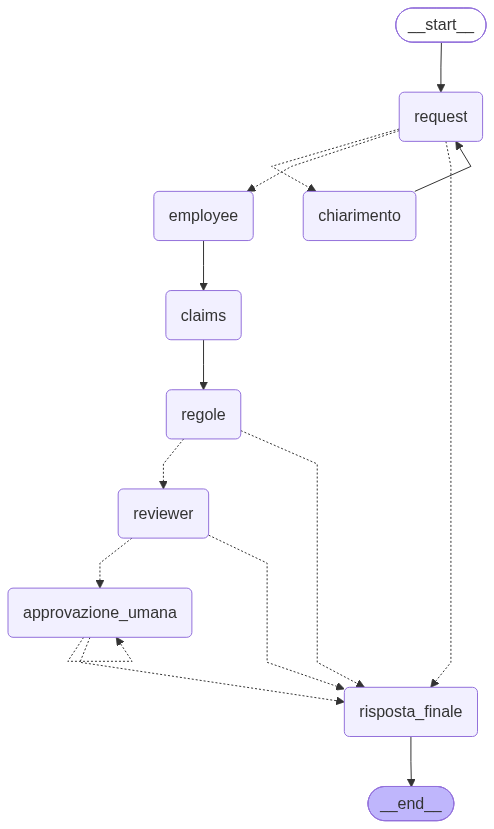

In [ ]:
from IPython.display import Image, display
display(Image(expense_graph.get_graph().draw_mermaid_png()))

## 15. Test del workflow completo

I test verificano quattro percorsi: `CLM001` per l'approvazione automatica, `CLM003` per il rifiuto dovuto alla ricevuta mancante, `CLM002` per l'approvazione umana poi negata e una richiesta senza data per il chiarimento.

Ogni nuova richiesta usa un `thread_id` distinto. Nei casi di `CLM002` e del chiarimento, il grafo viene ripreso con lo stesso `thread_id`: nel secondo caso forniamo la data mancante e verifichiamo che il Request Agent la interpreti prima di arrivare alla risposta finale.

In [ ]:
casi_test = [
    (
        "CLM001",
        "Sono il dipendente E001. Vorrei sapere se la spesa CLM001 "
        "per il treno da 110 EUR del 2026-10-08 può essere rimborsata."
    ),
    (
        "CLM003",
        "Sono il dipendente E001. Vorrei sapere se la spesa CLM003 "
        "per la cena da 48 EUR del 2026-10-08 può essere rimborsata."
    )
]

for claim_id, richiesta in casi_test:
    # Ogni prova usa un thread nuovo, con uno stato indipendente.
    config_test = {
        "configurable": {"thread_id": f"test-{claim_id}-{uuid4().hex}"}
    }

    risultato = expense_graph.invoke(
        {
            "input_originale": richiesta,
            "errori": []
        },
        config=config_test
    )

    print(f"\n{claim_id}")
    print("Esito delle regole:", risultato.get("deterministic_result"))
    print("Reviewer coerente:", risultato.get("reviewer_coerente"))

    if risultato.get("__interrupt__"):
        print("Workflow in pausa:", risultato["__interrupt__"][0].value)
    else:
        print("Risposta finale:", risultato.get("risposta_finale"))


CLM001
Esito delle regole: APPROVABILE
Reviewer coerente: True
Risposta finale: Richiesta CLM001: APPROVABILE. Dipendente, categoria, ricevuta e importo rispettano la policy. Approvazione automatica secondo la policy.

CLM003
Esito delle regole: NON_APPROVABILE
Reviewer coerente: True
Risposta finale: Richiesta CLM003: NON_APPROVABILE. Manca la ricevuta obbligatoria.


In [ ]:
richiesta_clm002 = (
    "Sono il dipendente E002. Vorrei sapere se la spesa CLM002 "
    "per l'hotel da 240 EUR del 2026-10-08 può essere rimborsata."
)

# Conserva questa configurazione: servirà per riprendere la stessa richiesta.
config_clm002 = {
    "configurable": {"thread_id": f"test-clm002-{uuid4().hex}"}
}

risultato_clm002 = expense_graph.invoke(
    {
        "input_originale": richiesta_clm002,
        "errori": []
    },
    config=config_clm002
)

print("Esito delle regole:", risultato_clm002.get("deterministic_result"))
print("Motivazione:", risultato_clm002.get("deterministic_reason"))
print("Reviewer coerente:", risultato_clm002.get("reviewer_coerente"))

if risultato_clm002.get("__interrupt__"):
    print("Workflow in pausa per approvazione:")
    print(json.dumps(
        risultato_clm002["__interrupt__"][0].value,
        indent=2,
        ensure_ascii=False
    ))
else:
    print("Risposta finale:", risultato_clm002.get("risposta_finale"))
    print("Errori:", risultato_clm002.get("errori"))

Esito delle regole: NECESSARIA_APPROVAZIONE
Motivazione: L'importo di 240 EUR supera la soglia di 180 EUR.
Reviewer coerente: True
Workflow in pausa per approvazione:
{
  "tipo": "approvazione_umana",
  "domanda": "Approvi questa richiesta di rimborso?",
  "claim_id": "CLM002",
  "importo": 240,
  "valuta": "EUR",
  "esito_preliminare": "NECESSARIA_APPROVAZIONE",
  "motivazione": "L'importo di 240 EUR supera la soglia di 180 EUR.",
  "revisione": "L'esito è coerente con i dati: l'importo di 240 EUR supera la soglia di approvazione (180 EUR) definita nella policy, giustificando correttamente lo stato NECESSARIA_APPROVAZIONE. Il claim rispetta inoltre il limite massimo per tipologia (300 EUR) e i requisiti del ruolo."
}


In [ ]:
risultato_rifiuto = expense_graph.invoke(
    Command(resume={
        "approvato": False,
        "nota": "Spesa non autorizzata dal responsabile."
    }),
    config=config_clm002
)

print("Decisione umana:", risultato_rifiuto.get("human_decision"))
print("Esito finale:", risultato_rifiuto.get("esito"))
print("Risposta finale:", risultato_rifiuto.get("risposta_finale"))

Decisione umana: RIFIUTATO
Esito finale: NON_APPROVABILE
Risposta finale: Richiesta CLM002: NON_APPROVABILE. L'importo di 240 EUR supera la soglia di 180 EUR. Il responsabile ha rifiutato la richiesta. Nota del responsabile: Spesa non autorizzata dal responsabile.


In [ ]:
config_chiarimento = {
    "configurable": {"thread_id": f"test-chiarimento-{uuid4().hex}"}
}

risultato_chiarimento = expense_graph.invoke(
    {
        "input_originale": (
            "Sono il dipendente E001. La spesa CLM001 è per un treno "
            "da 110 EUR. Posso ottenere il rimborso?"
        ),
        "errori": []
    },
    config=config_chiarimento
)

print("Campi mancanti:", risultato_chiarimento.get("missing_info"))

if risultato_chiarimento.get("__interrupt__"):
    print("Domanda di chiarimento:")
    print(json.dumps(
        risultato_chiarimento["__interrupt__"][0].value,
        indent=2,
        ensure_ascii=False
    ))
else:
    print("Risposta finale:", risultato_chiarimento.get("risposta_finale"))
    print("Errori:", risultato_chiarimento.get("errori"))

Campi mancanti: ['expense_date']
Domanda di chiarimento:
{
  "tipo": "chiarimento",
  "domanda": "Per valutare il rimborso, indica: la data della spesa.",
  "campi_mancanti": [
    "la data della spesa"
  ]
}


In [ ]:
risultato_chiarito = expense_graph.invoke(
    Command(resume="La spesa è del 2026-10-08."),
    config=config_chiarimento
)

print("Data interpretata:", risultato_chiarito.get("expense_date"))
print("Esito delle regole:", risultato_chiarito.get("deterministic_result"))
print("Risposta finale:", risultato_chiarito.get("risposta_finale"))

if risultato_chiarito.get("__interrupt__"):
    print("Nuova pausa:", risultato_chiarito["__interrupt__"][0].value)

Data interpretata: 2026-10-08
Esito delle regole: APPROVABILE
Risposta finale: Richiesta CLM001: APPROVABILE. Dipendente, categoria, ricevuta e importo rispettano la policy. Approvazione automatica secondo la policy.
